# Pizza Delivery Market: Demand Estimation, Merger Simulation, and a Delivery-Time Regulation

Structural industrial organization analysis of a differentiated-products market using a random-coefficients logit demand model (BLP) estimated with [`pyblp`](https://pyblp.readthedocs.io/).

**Questions answered**

1. How price-sensitive are consumers, and how do they substitute between pizza brands and the outside option?
2. What are marginal costs, markups, profits, market concentration (HHI), and consumer surplus at the estimated equilibrium?
3. What happens to prices, markups, profits, and consumer welfare if four of the six firms merge?
4. What happens if a regulator caps delivery time at 35 minutes?

**Data:** simulated panel of 20 markets, 6 firms, 500 products (`data/products_pizza.csv`) and 20,000 simulated consumers with income draws (`data/agents_pizza.csv`).

| Variable | Description |
|---|---|
| `prices` | Price of the product |
| `shares` | Market share |
| `deliverytime` | Delivery time in hours (35 minutes = 0.583) |
| `maxdeliverytime` | Delivery time capped at 35 minutes (used in the counterfactual) |
| `rating` | Customer rating |
| `hourlywages` | Local driver wage (cost shifter) |
| `demand_instruments*`, `supply_instruments*` | Instruments for price |
| `invincome` | Inverse household income (agent data) |

## Setup

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyblp

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

pyblp.options.digits = 2
pyblp.options.verbose = False
pyblp.__version__

'1.1.2'

## Data

In [2]:
agent_data = pd.read_csv("data/agents_pizza.csv")
product_data = pd.read_csv("data/products_pizza.csv")

In [3]:
# Checking:

unique_counts_df = product_data.nunique().reset_index()
unique_counts_df.columns = ['column_name', 'num_unique_values']
print(unique_counts_df)


            column_name  num_unique_values
0            Unnamed: 0                500
1            market_ids                 20
2              firm_ids                  6
3                shares                500
4   demand_instruments0                500
5   demand_instruments1                500
6   demand_instruments2                120
7   demand_instruments3                120
8   demand_instruments4                500
9   supply_instruments0                500
10  supply_instruments1                500
11  supply_instruments2                500
12  supply_instruments3                120
13  supply_instruments4                120
14  supply_instruments5                120
15               prices                500
16         deliverytime                500
17               rating                500
18          hourlywages                500
19      maxdeliverytime                278


In [4]:
product_data.head()

,Unnamed: 0,market_ids,firm_ids,shares,demand_instruments0,demand_instruments1,demand_instruments2,demand_instruments3,demand_instruments4,supply_instruments0,supply_instruments1,supply_instruments2,supply_instruments3,supply_instruments4,supply_instruments5,prices,deliverytime,rating,hourlywages,maxdeliverytime
0,0,0,0,0.01,2.87,1.79,7.93,10.57,0.58,2.87,2.03,1.79,7.93,10.66,10.57,4.95,0.33,0.14,0.58,0.33
1,1,0,0,0.00,2.31,1.30,7.93,10.57,0.88,2.31,1.73,1.30,7.93,10.66,10.57,7.17,0.89,0.63,0.88,0.58
2,2,0,0,0.00,2.45,1.27,7.93,10.57,0.61,2.45,2.00,1.27,7.93,10.66,10.57,6.10,0.75,0.66,0.61,0.58
3,3,0,0,0.01,2.44,1.50,7.93,10.57,0.25,2.44,2.36,1.50,7.93,10.66,10.57,5.20,0.76,0.43,0.25,0.58
4,4,0,0,0.01,2.73,1.87,7.93,10.57,0.30,2.73,2.31,1.87,7.93,10.66,10.57,3.70,0.47,0.06,0.30,0.47


In [5]:
unique_counts_df = agent_data.nunique().reset_index()
unique_counts_df.columns = ['column_name', 'num_unique_values']
print(unique_counts_df)

  column_name  num_unique_values
0  Unnamed: 0              20000
1  market_ids                 20
2      nodes0              20000
3      nodes1              20000
4     weights                  1
5   invincome              20000


## 1. Demand and Supply Estimation

**Specification**

* **Mean utility (X1):** price, delivery time, rating. No intercept, since the outside good's utility is normalized to zero.
* **Consumer heterogeneity (X2):** a random coefficient on the constant and on price, with price sensitivity interacted with inverse income (`invincome`), so lower-income consumers can be more price-sensitive.
* **Marginal cost (X3):** linear in rating, hourly wages, and delivery time.
* **Integration:** Halton draws, 50 per market. **Estimation:** two-step GMM with L-BFGS-B.

In [6]:
product_formulations = (
    
        # Linear, Mean Utility
        # There is no intercept because the mu of the outside option intercept = 0
    pyblp.Formulation('0 + prices + deliverytime + rating'),
    
        # Nonlinear, heterogeneity in utility
        # There is heterogeneity in the intercept
    pyblp.Formulation('1 + prices'),

        # Marginal Cost, linear
    pyblp.Formulation('1 + rating + hourlywages + deliverytime')         
)
product_formulations

(prices + deliverytime + rating,
 1 + prices,
 1 + rating + hourlywages + deliverytime)

In [7]:
# Specify how consumer demographics enters the model
# No intercept because the outside option is normalized to 0 utility

agent_formulation = pyblp.Formulation('0 + invincome')
agent_formulation

invincome

In [8]:
problem = pyblp.Problem(
    
    product_formulations,
    product_data,
    agent_formulation,
    agent_data,
    #costs_type="log",
    
        # Define an Integration configuration to solve the market share integral:
            # Monte Carlo Simulation w/ 50 simulated draws per market
    integration=pyblp.Integration("halton", 50, specification_options={'seed': 1}),
    
)
problem

Dimensions:
 T    N    F    I     K1    K2    K3    D    MD    MS 
---  ---  ---  ----  ----  ----  ----  ---  ----  ----
20   500   6   1000   3     2     4     1    7     10 

Formulations:
        Column Indices:              0           1             2            3      
-------------------------------  ---------  ------------  -----------  ------------
  X1: Linear Characteristics      prices    deliverytime    rating                 
 X2: Nonlinear Characteristics       1         prices                              
X3: Linear Cost Characteristics      1         rating     hourlywages  deliverytime
        d: Demographics          invincome                                         

In [9]:
# sigma: covariance of random coefficients (constant, price)
# pi:    interactions of demographics (invincome) with X2 characteristics
# beta:  linear utility parameters (X1)
# gamma: marginal cost parameters (X3)

results = problem.solve(
    sigma=[[1, 0], [0, 0]],
    pi=[[0], [-1.5]],
    beta=[-1, 1, 0.5],
    gamma=[0.5, 0.5, 1, 1],
    optimization=pyblp.Optimization("l-bfgs-b", {"gtol": 1e-5}),
)
results

Problem Results Summary:
GMM   Objective    Projected    Reduced Hessian  Reduced Hessian  Clipped  Weighting Matrix  Covariance Matrix
Step    Value    Gradient Norm  Min Eigenvalue   Max Eigenvalue   Shares   Condition Number  Condition Number 
----  ---------  -------------  ---------------  ---------------  -------  ----------------  -----------------
 2    +8.3E+01     +5.9E-03        +0.0E+00         +7.3E+04         0         +2.2E+05          +4.6E+04     

Cumulative Statistics:
Computation  Optimizer  Optimization   Objective   Fixed Point  Contraction
   Time      Converged   Iterations   Evaluations  Iterations   Evaluations
-----------  ---------  ------------  -----------  -----------  -----------
 00:00:05       Yes         112           125         14244        45093   

Nonlinear Coefficient Estimates (Robust SEs in Parentheses):
Sigma:      1        prices   |   Pi:    invincome 
------  ----------  --------  |  ------  ----------
  1      +0.0E+00             |    1 

**Interpretation**

* **Price:** the mean price coefficient is negative (-0.23) and the price-by-inverse-income interaction is large and negative (-2.3), so price sensitivity rises sharply as income falls. Heterogeneity in price response runs through income rather than an unobserved random coefficient.
* **Delivery time** lowers utility (-1.2) and **rating** raises it (+1.5), both precisely estimated.
* **Costs:** wages (+2.1), rating (+1.2), and delivery time (+1.1) all raise marginal cost.
* **Caveat:** both sigma terms are estimated at their lower bound of zero (hence the zero minimum eigenvalue of the reduced Hessian). The data do not support extra unobserved taste dispersion beyond what income already captures, so the model behaves close to a logit with demographic interactions.

## 2. Elasticities and Diversion Ratios (Market 1)

In market 1, a 1% price increase lowers a product's own demand by **2.74%** on average (range 1.98% to 3.36%), while the average cross-price elasticity is only **0.05**. Demand is elastic, but each pizza competes weakly with any single rival.

Diversion ratios tell the same story: when a product's price rises, roughly half of the lost customers leave the market (the outside good) rather than switching to another pizza, and any single rival captures only a few percent. Consumers are more likely to skip ordering than to switch brands.

Diversion ratios tell the same story: when a product's price rises, **50.7%** of the lost customers leave the market (the outside good) rather than switching to another pizza, while any single rival captures only **2.1%** on average. Consumers are more likely to skip ordering than to switch brands.

In [10]:
Elasticities = results.compute_elasticities()
Diversions = results.compute_diversion_ratios()

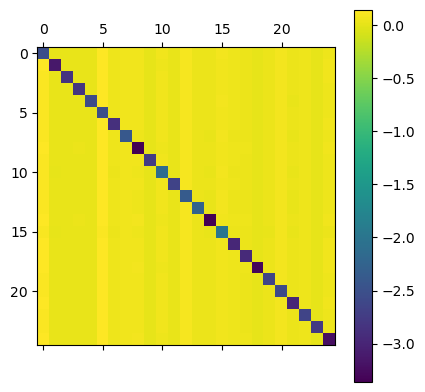

In [11]:
single_market = product_data['market_ids'] == 1
plt.colorbar(plt.matshow(Elasticities[single_market]));
#print (Elasticities[single_market])

In [12]:
#Assuming elasticities[single_market] gives a (J, J) matrix
elasticity_matrix = Elasticities[single_market]

#Own (diagonal) and Cross-Price (off-diagonal) Elasticities
own_elasticities = np.diag(elasticity_matrix)
avg_own = np.mean(own_elasticities)

cross_elasticities = elasticity_matrix.copy()
np.fill_diagonal(cross_elasticities, np.nan)
avg_cross = np.nanmean(cross_elasticities)

print("Average own-price elasticity:", avg_own)
print("Average cross-price elasticity:", avg_cross)
print("Min/Max own elasticities:", np.min(own_elasticities), np.max(own_elasticities))
print("Min/Max cross elasticities:", np.nanmin(cross_elasticities), np.nanmax(cross_elasticities))

Average own-price elasticity: -2.7420897589141675
Average cross-price elasticity: 0.05103689892739856
Min/Max own elasticities: -3.36114249182043 -1.982181867012641
Min/Max cross elasticities: 0.010104605016047036 0.14131158957256412


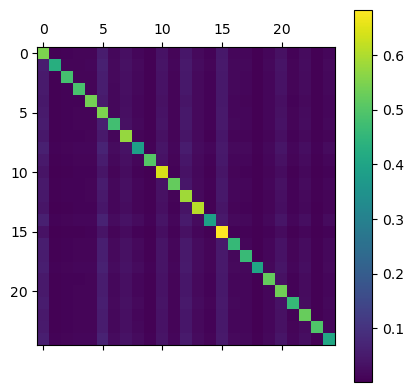

In [13]:
#diversion
plt.colorbar(plt.matshow(Diversions[single_market]));

In [14]:
# Diversion ratios for market 1 only. pyblp stores the diversion to the
# outside good on the diagonal of each market's matrix.
diversion_matrix = Diversions[single_market]

outside_diversion = np.diag(diversion_matrix)
inside_diversion = diversion_matrix.copy()
np.fill_diagonal(inside_diversion, np.nan)

print("Average diversion to outside good:", np.mean(outside_diversion))
print("Average diversion to each other inside good:", np.nanmean(inside_diversion))

Average diversion to outside good: 0.5068339314113013
Average diversion to each other inside good: 0.020548586191195782


## 3. Marginal Costs, Markups, Concentration, Profits, and Consumer Surplus

### 3.1 Marginal costs

Average marginal cost is **$3.23** per pizza (about $0.54 per slice), with a standard deviation of $0.97 and a range of $0.96 to $5.84. Against an average price near $5, this leaves a substantial margin.

Average: 3.2341385229008064
Standard deviation: 0.9721455680066264
Minimum: 0.9641107660686175
Maximum: 5.840951582214147


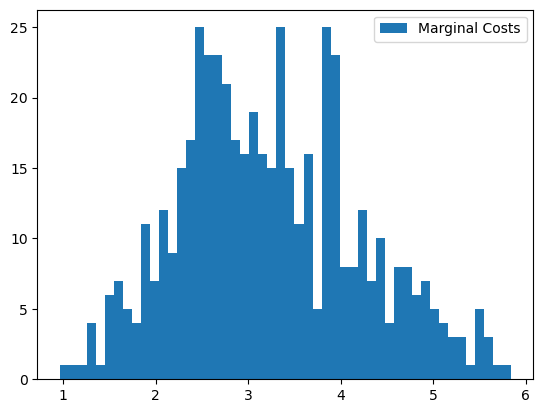

In [15]:
costs = results.compute_costs()
plt.hist(costs, bins=50);
plt.legend(["Marginal Costs"]);

#distribution summary
print("Average:", costs.mean())
print("Standard deviation:", costs.std())
print("Minimum:", costs.min())
print("Maximum:", costs.max())

### 3.2 Markups and the Lerner index

`compute_markups` returns the Lerner index, (P - MC) / P. The average markup is **0.37** (SD 0.07, range 0.21 to 0.59): price is about 37% above marginal cost.

For a single-product firm, profit maximization implies L = -1 / own-price elasticity. With an average own-price elasticity of -2.74 in market 1, this predicts L = 1 / 2.74 = **0.365**, very close to the estimated 0.373. The estimated markup is slightly higher because firms sell several products and internalize substitution between their own products when pricing.

Average: 0.373390275945313
Standard deviation: 0.06920501300310983
Minimum: 0.2121363107044166
Maximum: 0.593459127146321


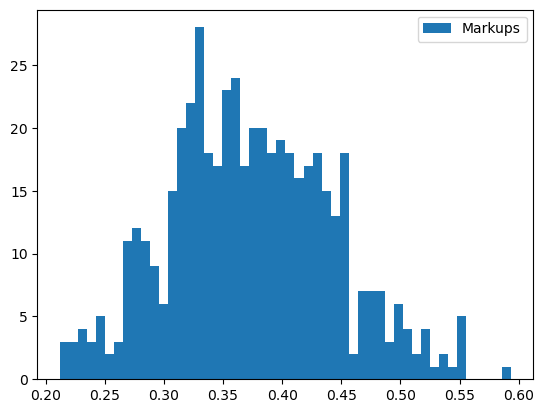

In [16]:
markups = results.compute_markups(costs=costs)
plt.hist(markups, bins=50);
plt.legend(["Markups"]);

#distribution summary
print("Average:", markups.mean())
print("Standard deviation:", markups.std())
print("Minimum:", markups.min())
print("Maximum:", markups.max())

### 3.3 Market concentration (HHI)

Average HHI is **1,884** (SD 195, range 1,699 to 2,369). No market reaches the 2,500 threshold for "highly concentrated" used in the 2010 Horizontal Merger Guidelines, although every market is above the 1,800 threshold used in the 2023 Merger Guidelines. With six firms, shares are fairly evenly spread.

Average: 1884.2560155828735
Standard deviation: 195.29400555934222
Minimum: 1698.7792005964502
Maximum: 2368.787808878105


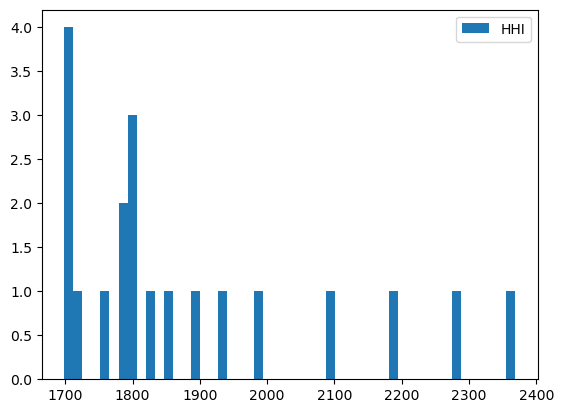

In [17]:
hhi = results.compute_hhi()
plt.hist(hhi, bins=50);
plt.legend(["HHI"]);

#distribution summary
print("Average:", hhi.mean())
print("Standard deviation:", hhi.std())
print("Minimum:", hhi.min())
print("Maximum:", hhi.max())

### 3.4 Profits

Scaled to a market of 1 million consumers with 6 slices per pizza, average variable profit is **$98,916 per product** (SD $73,772, range $16,456 to $443,337). The distribution is right-skewed: a few products earn far more than the rest.

Average: 98916.12698887676
Standard deviation: 73772.38979408256
Minimum: 16456.15005048074
Maximum: 443336.84418374463


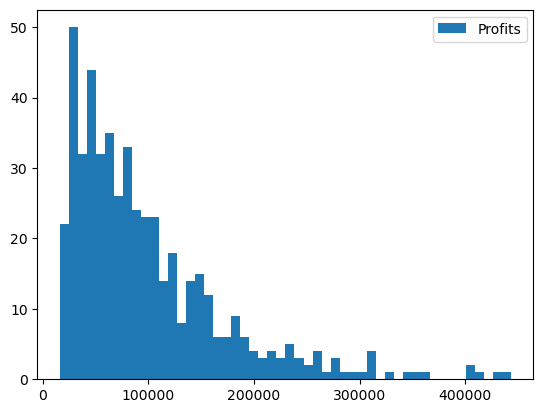

In [18]:
# pyblp reports profits per unit of market size (market size = 1).
# Scale to 1,000,000 consumers and 6 slices per pizza, as specified in the assignment.
MARKET_SIZE = 1_000_000
SLICES = 6

profits = results.compute_profits(costs=costs) * MARKET_SIZE * SLICES
plt.hist(profits, bins=50);
plt.legend(["Profits"]);

print("Average:", profits.mean())
print("Standard deviation:", profits.std())
print("Minimum:", profits.min())
print("Maximum:", profits.max())

### 3.5 Consumer surplus

Average consumer surplus is **$5.15 million per market** (SD $1.03M, range $2.81M to $6.59M), about $5.15 per consumer under the same scaling.

Average: 5150665.94800934
Standard deviation: 1026348.4883801867
Minimum: 2808208.2414386403
Maximum: 6593863.2121986905


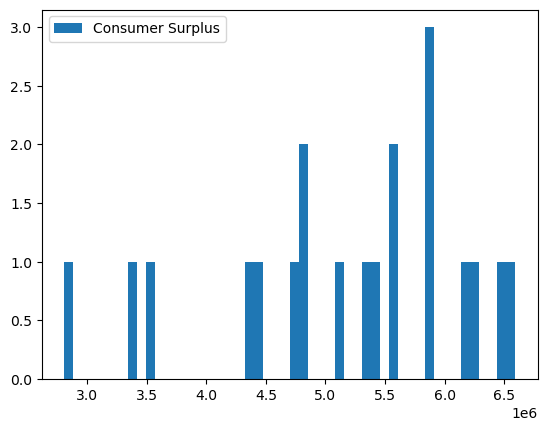

In [19]:
cs = results.compute_consumer_surpluses() * MARKET_SIZE * SLICES
plt.hist(cs, bins=50);
plt.legend(["Consumer Surplus"]);

print("Average:", cs.mean())
print("Standard deviation:", cs.std())
print("Minimum:", cs.min())
print("Maximum:", cs.max())

## 4. Merger Simulation

Firms 0, 2, and 3 are acquired by firm 1 (Fresh Brothers), leaving three firms. Post-merger prices are solved from the new Bertrand-Nash first-order conditions, holding marginal costs and demand fixed (no efficiencies).

In [20]:
# Firms 0, 2 and 3 become part of firm 1
product_data["merger_ids"] = product_data["firm_ids"].replace({0: 1, 2: 1, 3: 1})

In [21]:
# Checking:

unique_counts_df = product_data.nunique().reset_index()
unique_counts_df.columns = ['column_name', 'num_unique_values']
print(unique_counts_df)


            column_name  num_unique_values
0            Unnamed: 0                500
1            market_ids                 20
2              firm_ids                  6
3                shares                500
4   demand_instruments0                500
5   demand_instruments1                500
6   demand_instruments2                120
7   demand_instruments3                120
8   demand_instruments4                500
9   supply_instruments0                500
10  supply_instruments1                500
11  supply_instruments2                500
12  supply_instruments3                120
13  supply_instruments4                120
14  supply_instruments5                120
15               prices                500
16         deliverytime                500
17               rating                500
18          hourlywages                500
19      maxdeliverytime                278
20           merger_ids                  3


### 4.1 Prices, shares, and concentration

HHI rises by **2,576 points** on average (SD 462, range 1,502 to 3,509), to an average post-merger level of **4,460**. All 20 markets become highly concentrated under either the 2010 or the 2023 guidelines, so the merger would be presumed anticompetitive.

In [22]:
# Construct post-merger equilibrium prices
changed_prices = results.compute_prices(
    firm_ids=product_data['merger_ids'], 
    costs=costs)

# Construct post-merger market shares
changed_shares = results.compute_shares(changed_prices)

In [23]:
# Construct post-merger HHI
postmerger_hhi = results.compute_hhi(
    firm_ids=product_data['merger_ids'],
    shares=changed_shares)


# Count number of post-merger markets with HHI > 2500
num_high_hhi = (postmerger_hhi > 2500).sum()
print("Number of highly concentrated markets (HHI > 2500):", num_high_hhi)


Number of highly concentrated markets (HHI > 2500): 20


Average: 2575.8722174311138
Standard deviation: 462.12397042964915
Minimum: 1501.5564241761965
Maximum: 3509.2312725741003


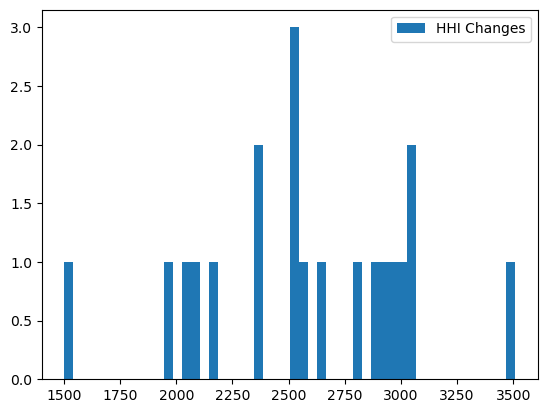

In [24]:
# Summarize the distribution of CHANGES in the HHI across markets.

diff_hhi = postmerger_hhi - hhi

plt.hist(diff_hhi, bins=50);
plt.legend(["HHI Changes"]);

#distribution summary
print("Average:", diff_hhi.mean())
print("Standard deviation:", diff_hhi.std())
print("Minimum:", diff_hhi.min())
print("Maximum:", diff_hhi.max())

Average: 4460.128233013987
Standard deviation: 485.1481202968092
Minimum: 3493.7432677257675
Maximum: 5290.443499754442


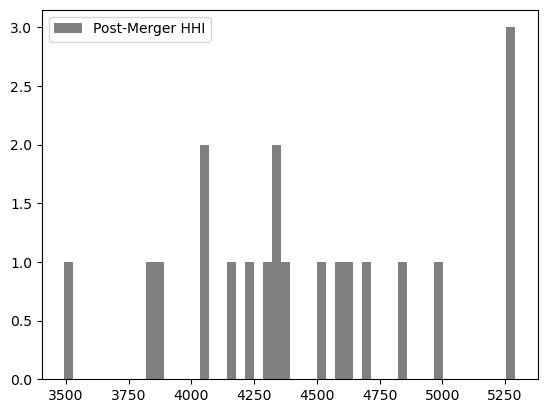

In [25]:
# Summarize the post-merger HHI

plt.hist(postmerger_hhi, bins=50, color='gray');
plt.legend(["Post-Merger HHI"]);

#distribution summary
print("Average:", postmerger_hhi.mean())
print("Standard deviation:", postmerger_hhi.std())
print("Minimum:", postmerger_hhi.min())
print("Maximum:", postmerger_hhi.max())

### 4.2 Markups

Markups rise by **0.062** on average, but the effect is concentrated in the merging firm:

* **Merged firm's products:** +0.087. Before the merger, a price increase sent some customers to what were rival brands; after the merger, many of those customers are recaptured by the same owner, so the firm raises prices.
* **Rival products:** +0.008. Prices are strategic complements, so rivals respond to the merged firm's higher prices with small increases of their own.

Average: 0.06190959907563
Standard deviation: 0.040416934727291555
Minimum: 0.0023661857644936557
Maximum: 0.14333392540443496


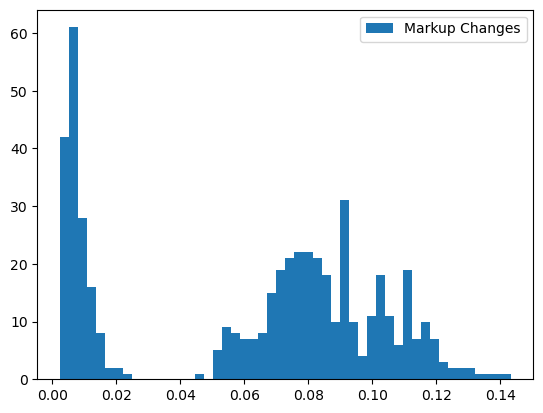

In [26]:
postmerger_markups = results.compute_markups(changed_prices, costs)

diff_markups = postmerger_markups - markups

plt.hist(diff_markups, bins=50);
plt.legend(["Markup Changes"]);

#distribution summary
print("Average:", diff_markups.mean())
print("Standard deviation:", diff_markups.std())
print("Minimum:", diff_markups.min())
print("Maximum:", diff_markups.max())


## 0.

**Looking at markup changes by the merged firm only**

Average: 0.08742168935780469
Standard deviation: 0.01901146344171794
Minimum: 0.046605493376513984
Maximum: 0.14333392540443496


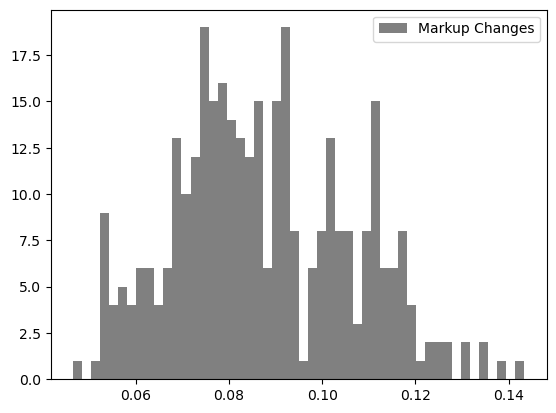

In [27]:
mergedfirm = product_data['merger_ids'] == 1
diff_markups_mergedfirm = postmerger_markups[mergedfirm]- markups[mergedfirm]

plt.hist(diff_markups_mergedfirm, bins=50, color='gray');
plt.legend(["Markup Changes"]);

#distribution summary
print("Average:", diff_markups_mergedfirm.mean())
print("Standard deviation:", diff_markups_mergedfirm.std())
print("Minimum:", diff_markups_mergedfirm.min())
print("Maximum:", diff_markups_mergedfirm.max())

**Looking at markup changes by the rival firms only**

Average: 0.007696407226008811
Standard deviation: 0.00381627399461215
Minimum: 0.0023661857644936557
Maximum: 0.024872100842652678


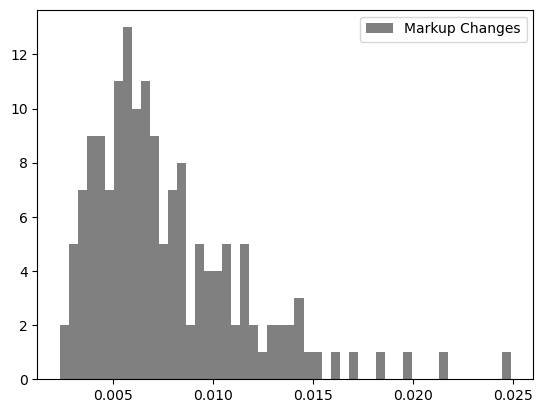

In [28]:
mergedfirm = product_data['merger_ids'] != 1
diff_markups_mergedfirm = postmerger_markups[mergedfirm]- markups[mergedfirm]

plt.hist(diff_markups_mergedfirm, bins=50, color='gray');
plt.legend(["Markup Changes"]);

#distribution summary
print("Average:", diff_markups_mergedfirm.mean())
print("Standard deviation:", diff_markups_mergedfirm.std())
print("Minimum:", diff_markups_mergedfirm.min())
print("Maximum:", diff_markups_mergedfirm.max())

### 4.3 Profits

Profit per product rises by **$9,312** on average. Notably, rivals gain more than the merging firm:

* **Merged firm's products:** +$6,318 on average
* **Rival products:** +$15,676 on average

This is the classic merger free-riding effect: the merged firm raises prices and gives up volume to do so, while outsiders capture the diverted customers at higher prices without bearing any of that cost.

Average: 9312.326706023672
Standard deviation: 9201.76327858733
Minimum: 519.2468170854663
Maximum: 66965.84632301232


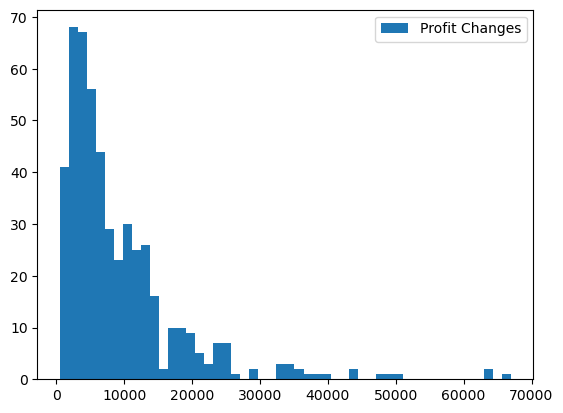

In [29]:
postmerger_profits = results.compute_profits(changed_prices, changed_shares, costs) * MARKET_SIZE * SLICES
diff_profits = postmerger_profits - profits

plt.hist(diff_profits, bins=50);
plt.legend(["Profit Changes"]);

print("Average:", diff_profits.mean())
print("Standard deviation:", diff_profits.std())
print("Minimum:", diff_profits.min())
print("Maximum:", diff_profits.max())

**Looking at profit changes by the merged firm only**

Average: 6317.87599675189
Standard deviation: 5264.440265356563
Minimum: 519.2468170854663
Maximum: 33408.340969624755


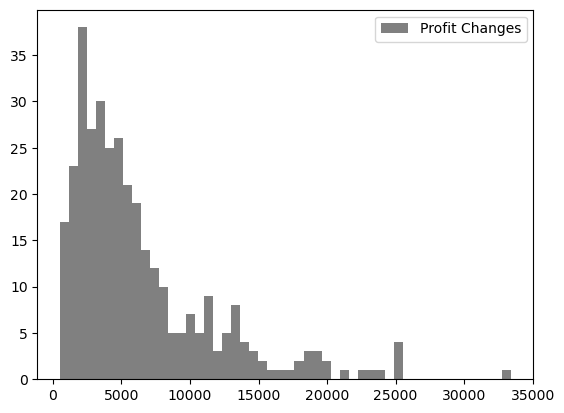

In [30]:
mergedfirm = product_data['merger_ids'] == 1

diff_profits_mergedfirm = postmerger_profits[mergedfirm] - profits[mergedfirm]

plt.hist(diff_profits_mergedfirm, bins=50, color='gray');
plt.legend(["Profit Changes"]);

#distribution summary
print("Average:", diff_profits_mergedfirm.mean())
print("Standard deviation:", diff_profits_mergedfirm.std())
print("Minimum:", diff_profits_mergedfirm.min())
print("Maximum:", diff_profits_mergedfirm.max())

**Looking at profit changes by the rival firms only**

Average: 15675.534463226213
Standard deviation: 12089.818826735771
Minimum: 2075.5451514836604
Maximum: 66965.84632301232


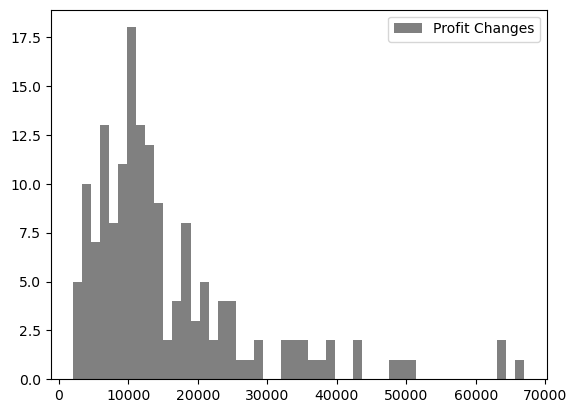

In [31]:
mergedfirm = product_data['merger_ids'] != 1

diff_profits_mergedfirm = postmerger_profits[mergedfirm] - profits[mergedfirm]

plt.hist(diff_profits_mergedfirm, bins=50, color='gray');
plt.legend(["Profit Changes"]);

#distribution summary
print("Average:", diff_profits_mergedfirm.mean())
print("Standard deviation:", diff_profits_mergedfirm.std())
print("Minimum:", diff_profits_mergedfirm.min())
print("Maximum:", diff_profits_mergedfirm.max())

### 4.4 Consumer surplus

Consumer surplus falls by **$668,094 per market** on average (SD $194,847; range -$973,124 to -$262,698), about a 13% loss relative to the pre-merger level. Every market loses, and markets with larger HHI increases lose more, as the scatter plot shows.

Average: -668093.6331882976
Standard deviation: 194846.66543780247
Minimum: -973123.9361467808
Maximum: -262698.2893956583


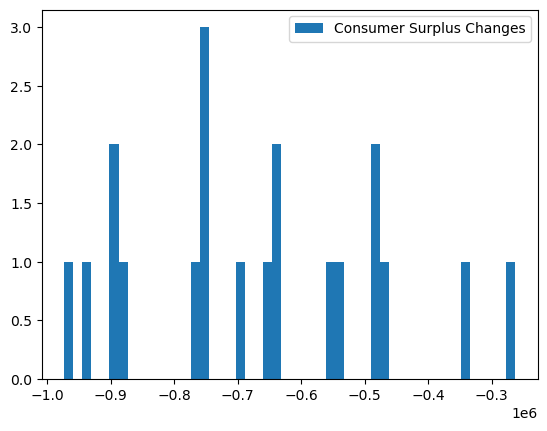

In [32]:
postmerger_cs = results.compute_consumer_surpluses(changed_prices) * MARKET_SIZE * SLICES
diff_cs = postmerger_cs - cs

plt.hist(diff_cs, bins=50);
plt.legend(["Consumer Surplus Changes"]);

print("Average:", diff_cs.mean())
print("Standard deviation:", diff_cs.std())
print("Minimum:", diff_cs.min())
print("Maximum:", diff_cs.max())

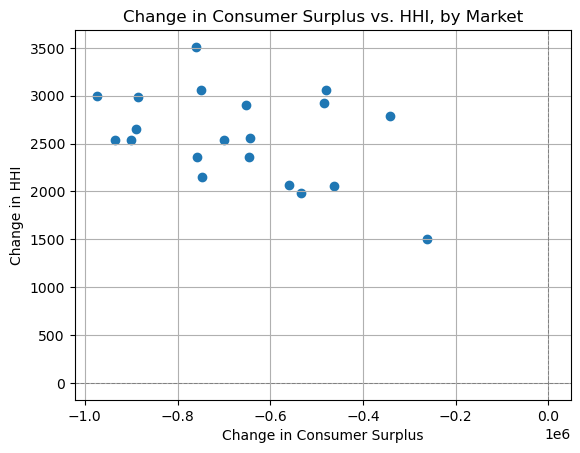

In [33]:
# Scatter plot: change in HHI vs. change in consumer surplus
plt.scatter(diff_cs, diff_hhi)
plt.xlabel("Change in Consumer Surplus")
plt.ylabel("Change in HHI")
plt.title("Change in Consumer Surplus vs. HHI, by Market")
plt.grid(True)
plt.axhline(0, color='gray', linestyle='--', linewidth=0.7)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.7)
plt.show()


## 5. Counterfactual: 35-Minute Delivery Cap

Without the merger, delivery time is capped at 35 minutes (`maxdeliverytime`). The new equilibrium is simulated at the estimated parameters, holding unobserved demand shocks (xi) and cost shocks (omega) fixed. The simulation uses the same Halton integration as estimation, so differences from the baseline reflect the policy, not a change in simulation draws.

In [34]:
# Reload the original data (undo the merger ownership change)
agent_data = pd.read_csv("data/agents_pizza.csv")
product_data = pd.read_csv("data/products_pizza.csv")

In [35]:
product_data.describe()

,Unnamed: 0,market_ids,firm_ids,shares,demand_instruments0,demand_instruments1,demand_instruments2,demand_instruments3,demand_instruments4,supply_instruments0,supply_instruments1,supply_instruments2,supply_instruments3,supply_instruments4,supply_instruments5,prices,deliverytime,rating,hourlywages,maxdeliverytime
count,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00
mean,249.50,9.50,2.40,0.01,1.63,1.69,10.56,10.99,0.48,1.63,1.53,1.69,10.56,9.94,10.99,5.09,0.51,0.53,0.48,0.42
std,144.48,5.77,1.75,0.01,0.58,0.56,1.20,1.34,0.27,0.58,0.54,0.56,1.20,1.63,1.34,1.17,0.29,0.29,0.27,0.19
min,0.00,0.00,0.00,0.00,0.10,0.16,7.06,7.31,0.00,0.10,0.09,0.16,7.06,6.59,7.31,2.17,0.00,0.00,0.00,0.00
25%,124.75,4.75,1.00,0.00,1.24,1.31,9.86,10.34,0.26,1.24,1.14,1.31,9.86,8.70,10.34,4.24,0.25,0.26,0.26,0.25
50%,249.50,9.50,2.00,0.01,1.64,1.71,10.64,11.06,0.48,1.64,1.49,1.71,10.64,9.82,11.06,5.02,0.51,0.55,0.48,0.51
75%,374.25,14.25,4.00,0.01,2.02,2.07,11.44,11.71,0.70,2.02,1.89,2.07,11.44,11.18,11.71,5.88,0.77,0.80,0.70,0.58
max,499.00,19.00,5.00,0.05,3.30,3.38,12.85,14.14,1.00,3.30,3.32,3.38,12.85,14.19,14.14,8.05,1.00,1.00,1.00,0.58


In [36]:
# Using exactly the same simulated consumers as the estimation (50 Halton draws per market),
# so differences from the baseline reflect the policy, not a change in draws
agents = results.problem.agents
est_agent_data = pd.DataFrame({
    "market_ids": agents.market_ids.flatten(),
    "weights": agents.weights.flatten(),
    "invincome": agents.demographics[:, 0],
})
for k in range(agents.nodes.shape[1]):
    est_agent_data[f"nodes{k}"] = agents.nodes[:, k]


def simulate(delivery_var):
    """Re-solve equilibrium with estimated parameters, replacing delivery time with delivery_var."""
    sim = pyblp.Simulation(
        product_formulations=(
            pyblp.Formulation(f"0 + prices + {delivery_var} + rating"),
            pyblp.Formulation("1 + prices"),
            pyblp.Formulation(f"1 + rating + hourlywages + {delivery_var}"),
        ),
        product_data=product_data,
        beta=results.beta,
        sigma=results.sigma,
        pi=results.pi,
        gamma=results.gamma,
        agent_formulation=pyblp.Formulation("0 + invincome"),
        agent_data=est_agent_data,
        xi=results.xi,
        omega=results.omega,
    )
    return sim, sim.replace_endogenous()


#check: with the original delivery times, the simulation should reproduce observed prices
_, baseline_check = simulate("deliverytime")
print("Max abs. price gap vs. observed:",
      np.abs(baseline_check.to_problem().products.prices.flatten() - product_data["prices"]).max())

simulation, simulation_results = simulate("maxdeliverytime")
simulation_results

Max abs. price gap vs. observed: 1.2576339969427863e-10


Simulation Results Summary:
Computation  Fixed Point  Fixed Point  Contraction  Profit Gradients  Profit Hessians  Profit Hessians
   Time       Failures    Iterations   Evaluations      Max Norm      Min Eigenvalue   Max Eigenvalue 
-----------  -----------  -----------  -----------  ----------------  ---------------  ---------------
 00:00:00         0           479          479          +4.3E-13         -3.4E-02         -5.2E-04    

In [37]:
sim_products = pd.DataFrame(pyblp.data_to_dict(simulation_results.to_problem().products))
simulated_prices = sim_products["prices"].to_numpy()
capped = product_data["deliverytime"] > 35 / 60   # products directly affected by the cap
print("Products affected by the cap:", capped.sum(), "of", len(capped))

Products affected by the cap: 223 of 500


### 5.1 Prices

The cap has two opposing effects on price. Shorter delivery lowers marginal cost (delivery time enters the cost function with a positive coefficient), which pushes prices down. It also raises product quality (delivery time enters utility negatively), which raises demand and pushes prices up.

The cost effect dominates. Prices fall by **$0.15** on average (SD $0.19, range -$0.80 to +$0.02). The decline is concentrated in capped products (**-$0.31**), while unaffected products fall slightly (**-$0.02**) as rivals respond to their improved competitors.

Average: -0.15052525569280595
Standard deviation: 0.18788962148694896
Minimum: -0.7952099977908071
Maximum: 0.021119403376184565
Average, capped products: -0.3080423872405137
Average, unaffected products: -0.0237154349883337


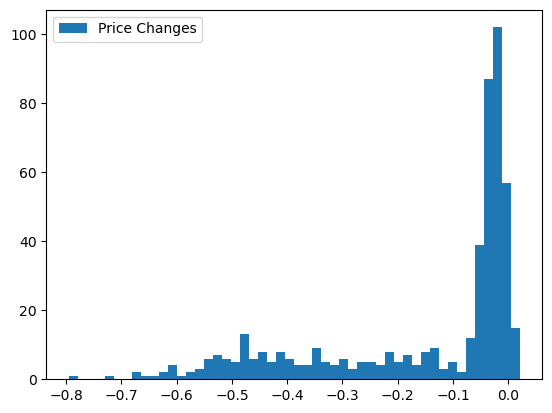

In [38]:
diff_prices = simulated_prices - product_data["prices"].to_numpy()

plt.hist(diff_prices, bins=50);
plt.legend(["Price Changes"]);

print("Average:", diff_prices.mean())
print("Standard deviation:", diff_prices.std())
print("Minimum:", diff_prices.min())
print("Maximum:", diff_prices.max())
print("Average, capped products:", diff_prices[capped].mean())
print("Average, unaffected products:", diff_prices[~capped].mean())

### 5.2 Marginal costs

Marginal costs fall only for products whose delivery time was cut; for all other products the change is zero up to numerical precision. The size of the drop follows directly from the cost coefficient on delivery time (about 1.1 per hour).

**Modeling caveat:** the cost function was estimated on observed delivery times, so it treats faster delivery as cheaper. In practice, forcing faster delivery would likely require more drivers or capacity and raise costs. The cost results should be read as the model's mechanical prediction, not as evidence that a cap saves firms money.

Marginal cost falls by **$0.23** on average for capped products and is unchanged for all other products, for an overall average of -$0.10.

Average: -0.10282602100442781
Average, capped products: -0.2305516165958946
Average, unaffected products: -4.799317782338727e-12


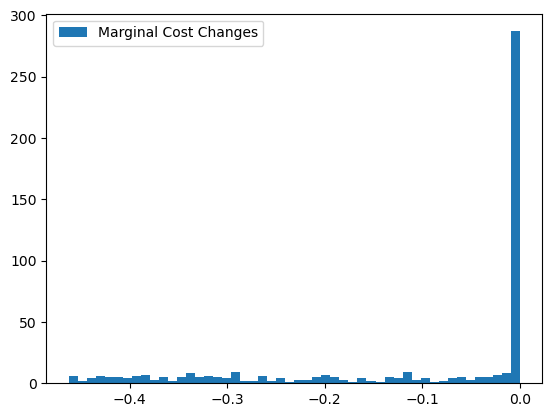

In [39]:
simulation_costs = simulation_results.compute_costs()
diff_costs = (simulation_costs - costs).flatten()

plt.hist(diff_costs, bins=50);
plt.legend(["Marginal Cost Changes"]);

print("Average:", diff_costs.mean())
print("Average, capped products:", diff_costs[capped].mean())
print("Average, unaffected products:", diff_costs[~capped].mean())

### 5.3 Markups

Markups barely move. Capped products' prices fall by more than their costs ($0.31 vs. $0.23), so the absolute margin narrows slightly, but because the price base also shrinks, the Lerner index rises marginally (**+0.007**). Unaffected products' markups fall slightly (**-0.003**) as they face stronger competition. Overall the change averages +0.001, so the cost savings are passed through to consumers rather than kept as margin.

Average: 0.0013858236812760321
Average, capped products: 0.007090877885404662
Average, unaffected products: -0.0032070538910008075


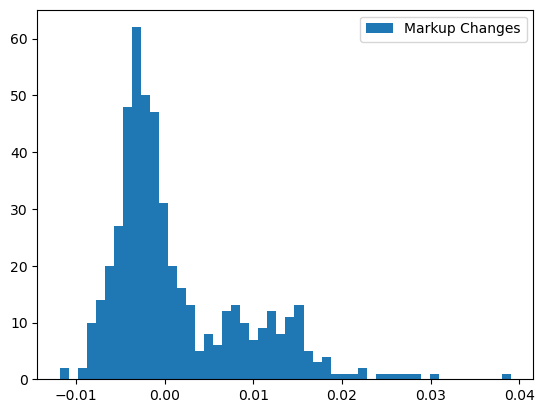

In [40]:
simulation_markups = simulation_results.compute_markups(simulated_prices, simulation_costs)
diff_markups = (simulation_markups - markups).flatten()

plt.hist(diff_markups, bins=50);
plt.legend(["Markup Changes"]);

print("Average:", diff_markups.mean())
print("Average, capped products:", diff_markups[capped].mean())
print("Average, unaffected products:", diff_markups[~capped].mean())

### 5.4 Consumer surplus and concentration

Consumer surplus rises in **every market**, by **$316,006** on average (SD $105,636, range $151,633 to $472,198), about a 6% gain over baseline. Two channels drive this: consumers directly value faster delivery, and prices fall. Concentration also declines slightly (average HHI change **-42**), as capped products, many of them previously slow, gain share.

Average: 316006.0461878878
Standard deviation: 105636.20642283633
Minimum: 151633.3981987536
Maximum: 472197.53873874526


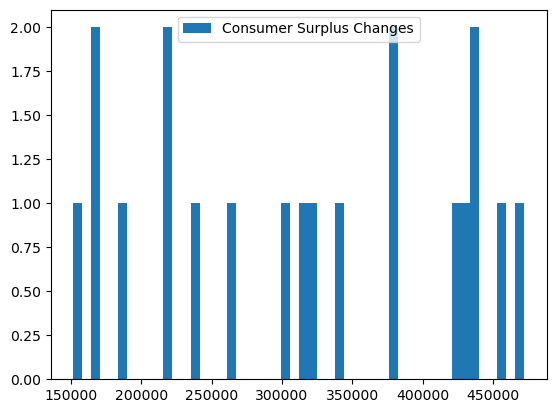

In [41]:
simulation_cs = simulation_results.compute_consumer_surpluses(simulated_prices) * MARKET_SIZE * SLICES
diff_cs_cap = simulation_cs - cs

plt.hist(diff_cs_cap, bins=50);
plt.legend(["Consumer Surplus Changes"]);

print("Average:", diff_cs_cap.mean())
print("Standard deviation:", diff_cs_cap.std())
print("Minimum:", diff_cs_cap.min())
print("Maximum:", diff_cs_cap.max())

Average HHI change: -42.48459079509075
Markets with HHI > 2,500: 0


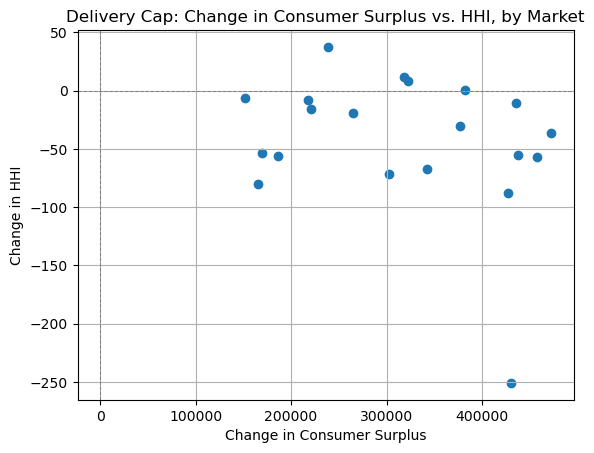

In [42]:
simulation_shares = simulation_results.compute_shares(simulated_prices)
simulation_hhi = simulation_results.compute_hhi(firm_ids=product_data["firm_ids"], shares=simulation_shares)
diff_hhi_cap = simulation_hhi - hhi

print("Average HHI change:", diff_hhi_cap.mean())
print("Markets with HHI > 2,500:", (simulation_hhi > 2500).sum())

plt.scatter(diff_cs_cap, diff_hhi_cap)
plt.xlabel("Change in Consumer Surplus")
plt.ylabel("Change in HHI")
plt.title("Delivery Cap: Change in Consumer Surplus vs. HHI, by Market")
plt.axhline(0, color="gray", linestyle="--", linewidth=0.7)
plt.axvline(0, color="gray", linestyle="--", linewidth=0.7)
plt.grid(True)
plt.show()

## 6. Conclusions

1. **Demand is elastic but substitution is mostly to the outside good.** Own-price elasticities average about -2.7, cross-price elasticities about 0.05, and roughly half of lost sales leave the market. Price sensitivity is driven by income.
2. **Estimated markups are consistent with theory.** The average Lerner index (0.37) is close to the inverse-elasticity benchmark (0.365).
3. **The four-firm merger is clearly anticompetitive.** HHI rises by about 2,600 points, the merged firm's markups rise by about 9 points, and consumer surplus falls by about $670K per market (about 13%), with no offsetting cost efficiencies modeled. Rivals gain more profit per product than the merging firm.
4. **The delivery cap raises consumer welfare.** Consumer surplus rises by about $316K per market (about 6%), through faster delivery and lower prices (-$0.31 on capped products), with markups nearly unchanged. This gain depends on the model treating faster delivery as cheaper, which follows from how the cost function was estimated; a real cap would likely raise costs, so this is an upper bound.